# 出租车 GPS 轨迹的来路记忆：条件互信息与马尔科夫阶数

**研究问题**：把城市划分成 $g\times g$ 网格，出租车的位置序列 $S_1,S_2,\dots$ 是否只由当前网格决定下一网格？
Rosvall 等 (2014, *Nat. Commun.*) 指出，真实网络流往往"记得来路"：$P(S_{t+1}\mid S_t,S_{t-1})\neq P(S_{t+1}\mid S_t)$，
一阶（无记忆）网络会把这种路径依赖平均掉。本 notebook 把记忆效应定义为：

> 在控制当前状态 $S_t$ 之后，历史状态是否仍能**显著降低**下一状态的不确定性。

对应的信息论判据是条件互信息 (CMI)：二阶 $I(S_{t+1};S_{t-1}\mid S_t)$，三阶 $I(S_{t+1};S_{t-2}\mid S_{t-1},S_t)$。
与此并列，我们还比较一/二/三阶马尔科夫模型在**同一轨迹**测试段上的对数似然，回答另一个问题："朴素高阶模型能否把这种信息转化为单轨迹预测收益"。这两个问题的答案可以不同，而且本实验中确实不同——这是本文的核心发现之一。

**实验设计一览**

| 因素 | 取值 | 为什么 |
|---|---|---|
| 网格分辨率 | 10×10, 20×20, 30×30 | 检验结论是否依赖空间尺度 |
| 序列形式 | 原始 / run-length 压缩 | GPS 采样密集，出租车大量时间停留在同一网格；压缩后剥离"停留"，只看真正的转移 |
| 记忆深度 | 二阶 CMI / 三阶 CMI | 判断可利用记忆集中在一步历史还是更深 |
| 零模型 | 条件置换 100 次 | 在 $S_t$（或 $(S_{t-1},S_t)$）相同的位置之间打乱历史，精确保留一阶结构、只破坏来路依赖 |
| 预测评估 | 测试段 (后 20%) LL/step | 判断"信息存在"是否等于"预测收益" |

| 网格参照系 | 逐轨迹包围盒 / 全局固定网格 | 检验结论是否依赖"网格编号的含义" |
| 平滑方式 | add-α / back-off | 区分"记忆不存在"与"朴素模型用不上记忆" |

**如何运行**：默认读取已有的逐文件结果（`memory_full_per_file.csv` 为逐轨迹网格，`memory_full_per_file_global.csv` 为全局网格；4307 个文件，2 进程各约 35 分钟生成）；将 `RUN_COMPUTE=True` 可重算，`CFG['grid_mode']` 决定重算哪一种。
依赖：`numpy pandas scipy matplotlib`，可选 `tqdm`。

In [1]:
import os, time, csv, importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from multiprocessing import Pool, cpu_count
from scipy import stats

try:
    from tqdm import tqdm
except ImportError:
    tqdm = lambda x, **k: x

RUN_COMPUTE = False
DATA_DIR    = './data/Taxi_070220'
SUMMARY_CSV = 'memory_full_summary.csv'
FIG_DIR     = 'figs'
os.makedirs(FIG_DIR, exist_ok=True)

CFG = dict(
    grids     = [10, 20, 30],
    alpha     = 0.5,          # add-alpha 平滑的伪计数
    beta      = 1.0,          # back-off 平滑的收缩强度（两种平滑同时计算，见第 3 节）
    n_perm    = 100,     # 每条轨迹的置换次数
    grid_mode = 'per_traj',   # 'per_traj': 每条轨迹按自身包围盒归一化（主结果）; 'global': 全体数据的固定网格（第 8 节稳健性）
    workers   = max(1, cpu_count() - 1),
)
PER_FILE_CSV = {'per_traj': 'memory_full_per_file.csv', 'global': 'memory_full_per_file_global.csv'}
NEED_COMPUTE = RUN_COMPUTE or not os.path.exists(PER_FILE_CSV[CFG['grid_mode']])
print('重新计算:', NEED_COMPUTE, '| 配置:', CFG)

重新计算: False | 配置: {'grids': [10, 20, 30], 'alpha': 0.5, 'beta': 1.0, 'n_perm': 100, 'grid_mode': 'per_traj', 'workers': 1}


## 1. 计算核心

下面的单元把全部计算函数写入 `taxi_memory_lib.py`。放在独立文件里是因为 Windows 的 `multiprocessing` 以 spawn 方式启动子进程，
子进程必须能 `import` 到 worker 函数；notebook 单元内定义的函数做不到这一点。每次运行该单元都会覆盖文件，所以代码只有这一份。

关键设计：

- **状态化**：`grid_mode='per_traj'` 把每条轨迹按自己的经纬度包围盒归一化到 $g\times g$ 网格。它只保证轨迹**内部**的转移结构有意义，
  同一个编号在不同轨迹里不是同一地点，因此不能做跨轨迹的地理解释；`grid_mode='global'` 用全体数据 0.5–99.5% 分位数作为固定边界。
- **压缩**：`compress_repeats` 合并连续重复状态。原始序列的"下一状态 = 当前状态"概率极高，任何阶的模型都退化为"留在原地"，CMI 也会被稀释到 0。
- **置换零模型**：`_perm_within_strata` 只在条件变量取值相同的位置之间打乱历史变量，于是零分布精确保留 $P(S_{t+1}\mid S_t)$，
  只破坏 $S_{t-1}$ 的额外影响。plug-in CMI 是有正偏差的，所以报告 `excess = real − 零分布均值`。
- **可复现**：随机种子由文件名的 CRC32 决定（旧代码用 `hash()`，受 `PYTHONHASHSEED` 影响，每次运行都不同）。

In [2]:
%%writefile taxi_memory_lib.py
"""
taxi_memory_lib.py —— 出租车轨迹记忆深度检验的计算核心
(由 taxi_memory_analysis.ipynb 自动生成；单独放在文件里是为了让 multiprocessing 在 Windows 上能 import 到 worker 函数)

每条轨迹 -> 网格状态序列 -> (可选) run-length 压缩 -> 按时间 80/20 划分
  - 一/二/三阶马尔科夫模型的测试集 per-step 对数似然
  - 二阶 CMI  I(S_{t+1}; S_{t-1} | S_t)        (置换零模型, 偏差校正)
  - 三阶 CMI  I(S_{t+1}; S_{t-2} | S_{t-1}, S_t)
"""
import os
import zlib
import numpy as np
from collections import defaultdict


# ---------------------------------------------------------------- 数据与状态化
def read_lat_lon(file_path):
    """读取 "id,time,lon,lat,..." 格式的 GPS 文件，返回 (lat, lon) 列表。"""
    lat, lon = [], []
    try:
        with open(file_path, "r", encoding="utf-8") as f:
            for line in f:
                cols = line.strip().split(",")
                if len(cols) >= 4:
                    try:
                        lon.append(float(cols[2]))
                        lat.append(float(cols[3]))
                    except ValueError:
                        continue
    except (FileNotFoundError, UnicodeDecodeError):
        return [], []
    return lat, lon


def scan_global_bounds(file_paths, lo_q=0.5, hi_q=99.5):
    """全局网格的经纬度边界：取所有点的 0.5%-99.5% 分位数，避免 GPS 漂移点把网格拉大。"""
    lats, lons = [], []
    for fp in file_paths:
        la, lo = read_lat_lon(fp)
        if la:
            lats.append(np.asarray(la))
            lons.append(np.asarray(lo))
    lat, lon = np.concatenate(lats), np.concatenate(lons)
    return (float(np.percentile(lat, lo_q)), float(np.percentile(lat, hi_q)),
            float(np.percentile(lon, lo_q)), float(np.percentile(lon, hi_q)))


def map_to_states(lat_list, lon_list, grid_size, bounds=None):
    """经纬度 -> g×g 网格编号。bounds=None: 每条轨迹按自身包围盒归一化; 否则用全局固定边界。"""
    if not lat_list:
        return []
    if bounds is None:
        a, b, c, d = min(lat_list), max(lat_list), min(lon_list), max(lon_list)
    else:
        a, b, c, d = bounds
    if abs(b - a) < 1e-9 or abs(d - c) < 1e-9:
        return [0] * len(lat_list)
    states = []
    for la, lo in zip(lat_list, lon_list):
        r = min(max(int((la - a) / (b - a) * grid_size), 0), grid_size - 1)
        co = min(max(int((lo - c) / (d - c) * grid_size), 0), grid_size - 1)
        states.append(r * grid_size + co)
    return states


def compress_repeats(states):
    """run-length 压缩：合并连续重复状态，剥离停留。"""
    out = states[:1]
    for s in states[1:]:
        if s != out[-1]:
            out.append(s)
    return out


def stable_seed(file_path):
    """只依赖文件名的种子（内置 hash() 受 PYTHONHASHSEED 影响，跨进程不可复现）。"""
    return zlib.crc32(os.path.basename(file_path).encode("utf-8")) & 0xFFFFFFFF


# ---------------------------------------------------------------- 马尔科夫模型
def fit_context_counts(states, order):
    """order 阶上下文 -> 下一状态计数。"""
    counts = defaultdict(lambda: defaultdict(int))
    for i in range(len(states) - order):
        counts[tuple(states[i:i + order])][states[i + order]] += 1
    return counts


def _smoothed(d, nxt, n_states, alpha, beta, smoothing, lower_p):
    """上下文计数 d 下 nxt 的概率。
    additive: (c + alpha) / (n + alpha*|S|)        —— 与早期结果一致；|S| 很大时先验极其分散
    backoff : (c + beta*p_lower) / (n + beta)       —— 向低阶分布收缩，样本少时自动退化为低阶模型
    d 为 None 表示该上下文在训练集中未出现：additive 退化为均匀分布，backoff 退化为低阶分布。
    """
    if d is None:
        return 1.0 / n_states if smoothing == "additive" else lower_p
    total = sum(d.values())
    if smoothing == "additive":
        return (d.get(nxt, 0) + alpha) / (total + alpha * n_states)
    return (d.get(nxt, 0) + beta * lower_p) / (total + beta)


def test_logliks(test, train, M1, M2, M3, n_states, alpha, beta=1.0, smoothing="additive"):
    """一/二/三阶模型在测试集上的总对数似然。
    三个阶的模型用**同一种**平滑：additive 时每阶独立 add-alpha；backoff 时 P0=均匀 -> P1 -> P2 -> P3 逐级收缩。
    （若一阶用 add-alpha、高阶用 backoff，ΔLL 会把"一阶先验过于分散"误记为高阶收益——见 notebook 第 3 节。）"""
    ll1 = ll2 = ll3 = 0.0
    p0 = 1.0 / n_states
    p2_, p1_, curr = train[-3], train[-2], train[-1]
    for s in test:
        p1 = _smoothed(M1.get((curr,)), s, n_states, alpha, beta, smoothing, p0)
        p2 = _smoothed(M2.get((p1_, curr)), s, n_states, alpha, beta, smoothing, p1) if (p1_, curr) in M2 else p1
        p3 = _smoothed(M3.get((p2_, p1_, curr)), s, n_states, alpha, beta, smoothing, p2) if (p2_, p1_, curr) in M3 else p2
        ll1 += np.log(p1)
        ll2 += np.log(p2)
        ll3 += np.log(p3)
        p2_, p1_, curr = p1_, curr, s
    return ll1, ll2, ll3, len(test)


# ---------------------------------------------------------------- 条件互信息 + 置换检验
def _H(codes, n):
    """整数编码序列的 plug-in 熵。"""
    counts = np.unique(codes, return_counts=True)[1]
    p = counts / n
    return -float(np.sum(p * np.log(p)))


def _perm_within_strata(x, strata, rng):
    """在 strata 相同的位置之间置换 x（保持 P(x|strata) 的边际结构）。"""
    order = np.argsort(strata, kind="stable")
    xs = x[order].copy()
    ss = strata[order]
    bnd = np.concatenate(([0], np.flatnonzero(np.diff(ss)) + 1, [len(ss)]))
    for a, b in zip(bnd[:-1], bnd[1:]):
        if b - a > 1:
            xs[a:b] = rng.permutation(xs[a:b])
    out = np.empty_like(x)
    out[order] = xs
    return out


def cmi_perm(states, order, n_perm, rng_seed):
    """order=2: I(S_{t+1}; S_{t-1} | S_t);  order=3: I(S_{t+1}; S_{t-2} | S_{t-1}, S_t).
    返回 real / excess(=real - 置换均值, 偏差校正) / p_value；序列过短返回 None。"""
    min_len = 30 if order == 2 else 50
    arr = np.asarray(states, dtype=np.int64)
    if len(arr) < min_len:
        return None
    lag = order - 1
    n = len(arr) - order
    hist = arr[:n]                                   # 被检验的远历史 (S_{t-1} 或 S_{t-2})
    nxt = arr[order:]                                # S_{t+1}
    K = int(arr.max()) + 1
    if order == 2:
        cond = arr[1:n + 1]                          # S_t
    else:
        cond = arr[1:n + 1] * K + arr[2:n + 2]       # (S_{t-1}, S_t) 联合编码
    Kc = int(cond.max()) + 1

    H_c = _H(cond, n)
    H_cn = _H(cond * K + nxt, n)

    def cmi(h):
        return _H(h * Kc + cond, n) + H_cn - H_c - _H((h * Kc + cond) * K + nxt, n)

    real = cmi(hist)
    rng = np.random.default_rng(rng_seed)
    null = np.array([cmi(_perm_within_strata(hist, cond, rng)) for _ in range(n_perm)])
    return {"real": float(real), "excess": float(real - null.mean()),
            "p_value": float((np.sum(null >= real) + 1) / (n_perm + 1))}


# ---------------------------------------------------------------- back-off 收缩强度 beta 的敏感性与内部验证调参
def _ll_orders(test, train, n_states, beta):
    """给定 beta 的 back-off 链 (P0 均匀 -> P1 -> P2 -> P3) 在 test 上的一/二/三阶 LL/step。"""
    M1, M2, M3 = (fit_context_counts(train, k) for k in (1, 2, 3))
    ll1, ll2, ll3, n = test_logliks(test, train, M1, M2, M3, n_states, 0.0, beta, "backoff")
    return ll1 / n, ll2 / n, ll3 / n


def backoff_sweep(args):
    """对一条轨迹：
    (1) beta 敏感性：对每个 beta 直接在测试段上算三阶 LL（用于画 ΔLL-beta 曲线）；
    (2) 调参：把训练段再按 75/25 切开，在内部验证段上为每个阶各选使其 LL 最大的 beta，
        然后用完整训练段重新拟合、在测试段上评估。这样 beta 的选择不看测试数据，ΔLL 是真正的样本外量。"""
    file_path, grid_size, do_compression, bounds, betas = args
    lat, lon = read_lat_lon(file_path)
    states = map_to_states(lat, lon, grid_size, bounds)
    if len(states) < 30:
        return None
    if do_compression:
        states = compress_repeats(states)
    if len(states) < 50:
        return None
    n_states = grid_size * grid_size
    cutoff = int(len(states) * 0.8)
    train, test = states[:cutoff], states[cutoff:]
    inner = int(len(train) * 0.75)
    tr_in, va_in = train[:inner], train[inner:]
    out = {"grid": grid_size, "compressed": do_compression, "file": os.path.basename(file_path), "comp_len": len(states)}
    val = {b: _ll_orders(va_in, tr_in, n_states, b) for b in betas}
    tst = {b: _ll_orders(test, train, n_states, b) for b in betas}
    for b in betas:
        out[f"ll1_b{b:g}"], out[f"ll2_b{b:g}"], out[f"ll3_b{b:g}"] = tst[b]
        out[f"val1_b{b:g}"], out[f"val2_b{b:g}"], out[f"val3_b{b:g}"] = val[b]       # 内部验证段 LL，供全局选 beta 用
    best = [max(betas, key=lambda b: val[b][k]) for k in range(3)]      # 每个阶各自的最优 beta（逐轨迹选）
    out["beta1"], out["beta2"], out["beta3"] = best
    out["ll1_tuned"], out["ll2_tuned"], out["ll3_tuned"] = tst[best[0]][0], tst[best[1]][1], tst[best[2]][2]
    out["delta_ll_2v1_tuned"] = out["ll2_tuned"] - out["ll1_tuned"]
    out["delta_ll_3v2_tuned"] = out["ll3_tuned"] - out["ll2_tuned"]
    return out


# ---------------------------------------------------------------- 单文件分析 (multiprocessing worker)
def analyze_file(args):
    """一条轨迹 × 一种 (网格, 压缩) 配置。两种平滑的 LL 在同一次遍历里一起算出（CMI 置换是主要开销，LL 几乎免费）。"""
    file_path, grid_size, alpha, do_compression, n_perm, bounds, beta = args
    lat, lon = read_lat_lon(file_path)
    states = map_to_states(lat, lon, grid_size, bounds)
    if len(states) < 30:
        return None
    raw_len = len(states)
    if do_compression:
        states = compress_repeats(states)
    if len(states) < 50:
        return None
    cutoff = int(len(states) * 0.8)
    train, test = states[:cutoff], states[cutoff:]
    n_states = grid_size * grid_size
    M1, M2, M3 = (fit_context_counts(train, k) for k in (1, 2, 3))
    ll1, ll2, ll3, n_test = test_logliks(test, train, M1, M2, M3, n_states, alpha, beta, "additive")
    ll1b, ll2b, ll3b, _ = test_logliks(test, train, M1, M2, M3, n_states, alpha, beta, "backoff")
    seed = stable_seed(file_path)
    c2 = cmi_perm(states, 2, n_perm, seed)
    c3 = cmi_perm(states, 3, n_perm, seed + 1)
    nan = float("nan")
    return {
        "grid": grid_size, "compressed": do_compression, "file": os.path.basename(file_path),
        "raw_len": raw_len, "comp_len": len(states),
        # add-alpha 平滑
        "ll1_per_step": ll1 / n_test, "ll2_per_step": ll2 / n_test, "ll3_per_step": ll3 / n_test,
        "delta_ll_2v1": (ll2 - ll1) / n_test, "delta_ll_3v1": (ll3 - ll1) / n_test, "delta_ll_3v2": (ll3 - ll2) / n_test,
        # back-off 平滑（一阶也用 back-off，三阶模型平滑方式一致）
        "ll1_bo_per_step": ll1b / n_test, "ll2_bo_per_step": ll2b / n_test, "ll3_bo_per_step": ll3b / n_test,
        "delta_ll_2v1_bo": (ll2b - ll1b) / n_test, "delta_ll_3v1_bo": (ll3b - ll1b) / n_test, "delta_ll_3v2_bo": (ll3b - ll2b) / n_test,
        # 条件互信息
        "cmi2_real": c2["real"] if c2 else nan, "cmi2_excess": c2["excess"] if c2 else nan, "cmi2_p": c2["p_value"] if c2 else nan,
        "cmi3_real": c3["real"] if c3 else nan, "cmi3_excess": c3["excess"] if c3 else nan, "cmi3_p": c3["p_value"] if c3 else nan,
    }

Writing taxi_memory_lib.py


## 2. 两个判据分别回答什么

**CMI（信息是否存在）**：$I(S_{t+1};S_{t-1}\mid S_t)=H(S_{t+1}\mid S_t)-H(S_{t+1}\mid S_t,S_{t-1})$，
单位 nat，度量"知道来路后下一步不确定性减少了多少"。它是非参数量，不依赖任何预测模型。

**测试集 LL/step（信息能否被朴素模型利用）**：在每条轨迹前 80% 上估计一/二/三阶转移概率，在后 20% 上评估。
二阶模型的上下文数最多 $|S|^2$，单条轨迹只有几百步，绝大多数上下文只出现一两次。

**期望**：

- 原始序列：停留主导 → 二阶/三阶 CMI 中位数 ≈ 0，个体显著比例 ≈ 5% 名义水平；
- 压缩序列：若存在来路记忆，二阶 CMI 显著为正；三阶 CMI 告诉我们记忆是否还更深；
- LL：若样本效率是瓶颈，二阶/三阶 ΔLL 可能为负——这不与 CMI 矛盾，而是两个问题的不同答案。

## 3. 平滑方式对 LL 比较的影响（方法上的注意点）

高阶模型的测试集 LL 取决于**未见/稀疏上下文如何平滑**，这里同时计算两种，一次遍历同时得到：

- **add-α**：$P(s'\mid c)=\dfrac{n(c,s')+\alpha}{n(c)+\alpha|S|}$。当 $|S|=400$（20×20）或 900（30×30）时，伪计数 $\alpha|S|=200\sim450$ 远大于单条轨迹里任何上下文的真实计数，
  高阶上下文越稀疏，预测分布越接近均匀分布——二阶模型在 LL 上"输给"一阶，很大程度上是**平滑先验过于分散**造成的，而不是数据里没有二阶信息。
  这也解释了为什么轨迹越长、ΔLL 反而越负（第 5 节）：长轨迹里更多测试步落在"见过但稀疏"的二阶上下文上。
- **back-off**（Chen & Goodman 1999 的插值形式）：$P_k(s'\mid c)=\dfrac{n(c,s')+\beta\,P_{k-1}(s'\mid c_{-1})}{n(c)+\beta}$，
  从 $P_0$=均匀分布开始逐级收缩：$P_0\to P_1\to P_2\to P_3$。样本少时自动退化为低阶模型，样本多时才偏离——这是语言模型里的标准做法。

一个容易踩的坑：**三个阶的模型必须用同一种平滑**。若一阶仍用 add-α 而二阶用 back-off，二阶的"收益"里会混进"一阶先验过于分散"这一项——
在 30×30 网格上单是把一阶模型从 add-α 换成 back-off 就能让 LL/step 提高 0.6 nat，足以把任何结论反转。因此 `*_bo` 列里一阶模型也用 back-off（`ll1_bo_per_step`）。

**期望**：若"二阶信息存在但朴素模型用不上"的解释成立，back-off 下 ΔLL(2 vs 1) 应由负转正，并且随轨迹长度**上升**而不是下降；
原始序列（CMI≈0 的阴性对照）上 ΔLL 应接近 0。列名约定：`delta_ll_*` 为 add-α，`delta_ll_*_bo` 为 back-off。

In [3]:
import taxi_memory_lib as lib
importlib.reload(lib)

FIELDS = ['grid', 'compressed', 'file', 'raw_len', 'comp_len', 'll1_per_step', 'll2_per_step', 'll3_per_step',
          'delta_ll_2v1', 'delta_ll_3v1', 'delta_ll_3v2',
          'll1_bo_per_step', 'll2_bo_per_step', 'll3_bo_per_step', 'delta_ll_2v1_bo', 'delta_ll_3v1_bo', 'delta_ll_3v2_bo',
          'cmi2_real', 'cmi2_excess', 'cmi2_p', 'cmi3_real', 'cmi3_excess', 'cmi3_p']

def load_results(path):
    d = pd.read_csv(path)
    d['stay_frac'] = np.where(d.compressed, 1 - d.comp_len / d.raw_len, np.nan)   # 被压缩掉的比例 = 停留比例（仅压缩行有意义）
    return d

if NEED_COMPUTE:
    files = sorted(os.path.join(DATA_DIR, f) for f in os.listdir(DATA_DIR) if os.path.isfile(os.path.join(DATA_DIR, f)))
    assert files, f'目录 {DATA_DIR} 中没有文件'
    bounds = lib.scan_global_bounds(files) if CFG['grid_mode'] == 'global' else None
    print(f'{len(files)} 个文件 | grid_mode={CFG["grid_mode"]} bounds={bounds} | {CFG["workers"]} 进程')
    t0 = time.time()
    with open(PER_FILE_CSV[CFG['grid_mode']], 'w', newline='', encoding='utf-8') as fh:
        w = csv.DictWriter(fh, fieldnames=FIELDS); w.writeheader()
        for g in CFG['grids']:
            for comp in (False, True):
                args = [(fp, g, CFG['alpha'], comp, CFG['n_perm'], bounds, CFG['beta']) for fp in files]
                if CFG['workers'] > 1:
                    with Pool(CFG['workers']) as pool:
                        it = pool.imap_unordered(lib.analyze_file, args, chunksize=20)
                        rows = [r for r in tqdm(it, total=len(args), desc=f'grid={g} comp={comp}') if r]
                else:
                    rows = [r for r in tqdm(map(lib.analyze_file, args), total=len(args), desc=f'grid={g} comp={comp}') if r]
                w.writerows(rows)
                print(f'  grid={g} compressed={comp}: 有效文件 {len(rows)}')
    print(f'总耗时 {time.time() - t0:.0f} s')

df = load_results(PER_FILE_CSV['per_traj'])          # 主结果：逐轨迹网格
print(f'逐文件记录 {len(df)} 行；原始序列有效轨迹 {df[~df.compressed].file.nunique()}，压缩后 {df[df.compressed].file.nunique()}')

逐文件记录 19548 行；原始序列有效轨迹 4307，压缩后 2243


## 4. 汇总：六种配置下的 CMI 与 LL

对每个 (网格, 原始/压缩) 组合汇总：

- `cmi*_median`：偏差校正 CMI 的中位数（nat）；`cmi*_sig05`：置换 $p<0.05$ 的轨迹比例（名义水平 5%）；`cmi*_wilcoxon_p`：跨轨迹单侧 Wilcoxon（$H_1$: excess 中位数 > 0）；
- `dll_2v1_median` / `dll_3v2_median`：add-α 平滑下测试段 ΔLL/step 中位数；`dll_*_pos`：高阶模型更好的轨迹比例；
- `dll_*_bo_*`：同上，但用 back-off 平滑；`dll_*_bo_wilcoxon_p`：跨轨迹单侧 Wilcoxon（$H_1$: ΔLL 中位数 > 0）。

In [4]:
def wilcoxon_greater(x):
    x = np.asarray(x); x = x[np.isfinite(x) & (x != 0)]
    return stats.wilcoxon(x, alternative='greater').pvalue if len(x) >= 10 else np.nan

def summarize(d):
    rows = []
    for (g, comp), s in d.groupby(['grid', 'compressed'], sort=True):
        rows.append(dict(grid=g, compressed=comp, n_files=len(s), stay_frac_median=s.stay_frac.median(), len_median=s.comp_len.median(),
                         cmi2_median=s.cmi2_excess.median(), cmi2_sig05=(s.cmi2_p < .05).mean(), cmi2_wilcoxon_p=wilcoxon_greater(s.cmi2_excess),
                         cmi3_median=s.cmi3_excess.median(), cmi3_sig05=(s.cmi3_p < .05).mean(), cmi3_wilcoxon_p=wilcoxon_greater(s.cmi3_excess),
                         dll_2v1_median=s.delta_ll_2v1.median(), dll_2v1_pos=(s.delta_ll_2v1 > 0).mean(),
                         dll_3v2_median=s.delta_ll_3v2.median(), dll_3v2_pos=(s.delta_ll_3v2 > 0).mean(),
                         dll_2v1_bo_median=s.delta_ll_2v1_bo.median(), dll_2v1_bo_pos=(s.delta_ll_2v1_bo > 0).mean(), dll_2v1_bo_wilcoxon_p=wilcoxon_greater(s.delta_ll_2v1_bo),
                         dll_3v2_bo_median=s.delta_ll_3v2_bo.median(), dll_3v2_bo_pos=(s.delta_ll_3v2_bo > 0).mean(), dll_3v2_bo_wilcoxon_p=wilcoxon_greater(s.delta_ll_3v2_bo)))
    return pd.DataFrame(rows)

summary = summarize(df)
summary.insert(0, 'grid_mode', 'per_traj')          # 汇总 CSV 在第 7 节与全局网格结果一起写出
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 40)
display(summary.drop(columns='grid_mode').round(5))

,grid,compressed,n_files,stay_frac_median,len_median,cmi2_median,cmi2_sig05,cmi2_wilcoxon_p,cmi3_median,cmi3_sig05,cmi3_wilcoxon_p,dll_2v1_median,dll_2v1_pos,dll_3v2_median,dll_3v2_pos,dll_2v1_bo_median,dll_2v1_bo_pos,dll_2v1_bo_wilcoxon_p,dll_3v2_bo_median,dll_3v2_bo_pos,dll_3v2_bo_wilcoxon_p
0,10,False,4307,NaN,1303.0,0.00000,0.04644,1.0,0.00000,0.04690,1.0,-0.00050,0.01532,-0.00082,0.00673,0.00095,0.54330,1.0,-0.00000,0.49454,1.0
1,10,True,2154,0.90055,167.0,0.02073,0.29062,0.0,0.00042,0.05757,0.0,-0.16910,0.08403,-0.02786,0.16806,-0.10537,0.14810,1.0,-0.06638,0.05246,1.0
2,20,False,4307,NaN,1303.0,0.00000,0.05665,1.0,0.00000,0.03622,1.0,-0.00338,0.00534,-0.00270,0.00302,0.00095,0.53471,1.0,-0.00001,0.49153,1.0
3,20,True,2230,0.81855,306.0,0.02713,0.55247,0.0,0.00058,0.07713,0.0,-0.07635,0.09731,-0.00929,0.17489,-0.05147,0.17623,1.0,-0.03634,0.03722,1.0
4,30,False,4307,NaN,1303.0,0.00000,0.06362,1.0,0.00000,0.03668,1.0,-0.00437,0.00325,-0.00226,0.00418,0.00095,0.53146,1.0,-0.00000,0.49362,1.0
5,30,True,2243,0.75345,416.0,0.02434,0.66251,0.0,0.00018,0.06152,0.0,-0.04164,0.11681,0.00000,0.19973,-0.03648,0.16719,1.0,-0.02461,0.03700,1.0


### 结果解读

1. **原始序列看不到记忆——这是预期中的"阴性对照"**：停留占原始序列的 75–90%（压缩行的 `stay_frac_median`），二阶/三阶 CMI 中位数为 0，
   显著比例 4.6%–6.4%（三阶 3.6%–4.7%），与 5% 名义水平无异，跨轨迹 Wilcoxon $p=1$。原始序列上的任何"记忆"结论都只是在描述停留。
2. **压缩后二阶来路记忆稳定出现**：三种网格下二阶 CMI 中位数 0.021 / 0.027 / 0.024 nat，个体显著比例 29% / 55% / 66%，跨轨迹 $p$ 数值下溢。
   网格越细显著比例越高——更细的网格让"来路"有更多可区分的方向，也使压缩后序列更长（检验功效更高，见第 5 节）。
3. **三阶残余极小**：三阶 CMI 中位数 0.0002–0.0006 nat，仅为二阶的 1–2%；显著比例 6–8%，略高于名义水平；跨轨迹检验可检出但效应量接近零。
   稳妥的表述是"三阶残余统计可检测、效应量接近零"，而不是"不存在三阶记忆"。
4. **朴素高阶模型没有单轨迹预测收益，且这一点不取决于 add-α**：add-α 下二阶相对一阶的 ΔLL/step 中位数为 −0.169 / −0.076 / −0.042，只有 8–12% 的轨迹二阶更好；
   换成 β=1 的 back-off 后负值缩小（−0.105 / −0.052 / −0.037，15–18% 更好）但符号不变。阴性对照成立：原始序列上 back-off 的 ΔLL 为 +0.001，二阶更优比例 53–54%，与其 CMI≈0 一致。
   β=1 只是 back-off 的一个任意取值，第 6 节会说明 ΔLL 的符号其实由 β 决定。

## 5. 检验功效：结果随序列长度如何变化

置换检验的功效随序列长度增加。如果"二阶记忆"是真实的，显著比例应随压缩后长度单调上升；如果三阶信号只是噪声，它应保持在 5% 附近不随长度变化；若三阶也随长度上升，则它是真实但微弱的效应。
同时观察 ΔLL 随长度的变化，可以区分"样本不足"与"平滑先验"两种解释：样本不足时长轨迹的 ΔLL 应改善，平滑先验主导时则不会。

In [5]:
comp = df[df.compressed].copy()
comp['len_q'] = comp.groupby('grid').comp_len.transform(lambda x: pd.qcut(x, 4, labels=False))
power = comp.groupby(['grid', 'len_q']).agg(n=('file', 'size'), len_median=('comp_len', 'median'),
                                            cmi2_median=('cmi2_excess', 'median'), cmi2_sig05=('cmi2_p', lambda p: (p < .05).mean()),
                                            cmi3_sig05=('cmi3_p', lambda p: (p < .05).mean()),
                                            dll_2v1_median=('delta_ll_2v1', 'median'), dll_2v1_pos=('delta_ll_2v1', lambda x: (x > 0).mean()),
                                            dll_2v1_bo_median=('delta_ll_2v1_bo', 'median'), dll_2v1_bo_pos=('delta_ll_2v1_bo', lambda x: (x > 0).mean())).reset_index()
display(power.round(4))
for g, s in comp.groupby('grid'):
    r1 = stats.spearmanr(s.comp_len, s.cmi2_excess).statistic
    r2 = stats.spearmanr(s.comp_len, s.delta_ll_2v1).statistic
    r3 = stats.spearmanr(s.comp_len, s.delta_ll_2v1_bo).statistic
    print(f'grid {g:2d}: Spearman(长度, 二阶CMI) = {r1:+.3f}   Spearman(长度, ΔLL 2v1 add-α) = {r2:+.3f}   Spearman(长度, ΔLL 2v1 back-off) = {r3:+.3f}')

grid 10: Spearman(长度, 二阶CMI) = +0.303   Spearman(长度, ΔLL 2v1 add-α) = -0.279   Spearman(长度, ΔLL 2v1 back-off) = -0.083
grid 20: Spearman(长度, 二阶CMI) = +0.441   Spearman(长度, ΔLL 2v1 add-α) = -0.271   Spearman(长度, ΔLL 2v1 back-off) = -0.140
grid 30: Spearman(长度, 二阶CMI) = +0.463   Spearman(长度, ΔLL 2v1 add-α) = -0.263   Spearman(长度, ΔLL 2v1 back-off) = -0.140


,grid,len_q,n,len_median,cmi2_median,cmi2_sig05,cmi3_sig05,dll_2v1_median,dll_2v1_pos,dll_2v1_bo_median,dll_2v1_bo_pos
0,10,0,541,95.0,0.0099,0.1516,0.0240,-0.0757,0.1701,-0.0748,0.1941
1,10,1,546,149.0,0.0155,0.2216,0.0458,-0.1635,0.0348,-0.1133,0.1081
2,10,2,528,186.0,0.0228,0.3068,0.0568,-0.1997,0.0227,-0.1150,0.0947
3,10,3,539,240.0,0.0351,0.4842,0.1039,-0.2317,0.1076,-0.1159,0.1948
4,20,0,558,156.0,0.0107,0.2437,0.0305,-0.0257,0.1900,-0.0208,0.2240
5,20,1,562,270.0,0.0243,0.5125,0.0641,-0.0749,0.0836,-0.0532,0.1530
6,20,2,556,339.0,0.0297,0.6349,0.0809,-0.0955,0.0468,-0.0612,0.1493
7,20,3,554,437.0,0.0441,0.8213,0.1336,-0.1052,0.0686,-0.0631,0.1787
8,30,0,563,208.0,0.0094,0.2948,0.0195,-0.0101,0.1954,-0.0182,0.1812
9,30,1,570,370.0,0.0226,0.6491,0.0421,-0.0410,0.1298,-0.0385,0.1702


**解读**：二阶 CMI 的显著比例随长度稳定上升（30×30 网格从最短四分位的 29% 升到最长四分位的 91%），二阶信号是真实且受功效限制的。
三阶显著比例同样随长度上升（最短四分位 2–3% → 最长四分位 10–13%），所以三阶残余不是纯噪声，而是一个**真实但微弱**的效应：它的中位数效应量只有二阶的 1–2%，只有在最长的轨迹上才能被检出。
与此同时，add-α 的 ΔLL(2 vs 1) 随长度**变得更负**（Spearman ≈ −0.27），这与"样本不足"的解释相反，支持第 3 节的判断：长轨迹里更多测试步落到见过但稀疏的二阶上下文上，被分散的 add-α 先验拉向均匀分布。
β=1 的 back-off 把这个相关系数缩到 −0.08 ～ −0.14，说明先验分散的问题缓解了但没有消除。

## 6. back-off 收缩强度 β 的敏感性与调参

第 4 节里 β=1 的 back-off 并没有让二阶模型优于一阶。β 控制高阶估计向低阶分布收缩的强度（β 越大越保守），它是一个必须调的超参数，而不是常数。
这一节做两件事（只涉及 LL，不涉及置换检验，所以很便宜，逐文件结果缓存在 `memory_backoff_sweep.csv`）：

1. **敏感性曲线**：对 β ∈ {0.3, 1, 2, 3, 5, 7, 10, 30, 100, 300} 直接在测试段上计算三阶 LL，画出 ΔLL 随 β 的变化。这是描述性的——β 在测试段上挑是乐观的，所以只用来看形状。
2. **不看测试数据的调参**：把训练段再按 75/25 切开，在内部验证段上选 β。有两种粒度：
   - *逐轨迹*：每条轨迹、每个阶各选自己的 β（验证段只有几十步，噪声大，偏保守）；
   - *全局*：把所有轨迹内部验证段的 LL 平均，每个阶选一个公共的 β*（稳定；这是本文报告的主要调参结果）。
   然后用完整训练段重新拟合，在测试段上评估。这样得到的 ΔLL 是真正的样本外量。

**期望**：若"二阶信息存在、β=1 只是收缩不够"成立，ΔLL(2 vs 1) 应随 β 增大由负转正并趋于平台；调参后的 ΔLL 应为正。三阶若无可利用信息，其曲线应贴着 0。
原始序列作为阴性对照，任何 β 下 ΔLL 都应≈0。

In [6]:
SWEEP_CSV = {'per_traj': 'memory_backoff_sweep.csv', 'global': 'memory_backoff_sweep_global.csv'}
BETAS = [0.3, 1, 2, 3, 5, 7, 10, 30, 100, 300]

def run_sweep(grid_mode, out_csv):
    files = sorted(os.path.join(DATA_DIR, f) for f in os.listdir(DATA_DIR) if os.path.isfile(os.path.join(DATA_DIR, f)))
    bounds = lib.scan_global_bounds(files) if grid_mode == 'global' else None
    rows = []
    for g in CFG['grids']:
        for comp in (False, True):
            args = [(fp, g, comp, bounds, BETAS) for fp in files]
            if CFG['workers'] > 1:
                with Pool(CFG['workers']) as pool:
                    rows += [r for r in tqdm(pool.imap_unordered(lib.backoff_sweep, args, chunksize=20), total=len(args), desc=f'sweep grid={g} comp={comp}') if r]
            else:
                rows += [r for r in map(lib.backoff_sweep, args) if r]
    pd.DataFrame(rows).to_csv(out_csv, index=False, float_format='%.6g')

if RUN_COMPUTE or not os.path.exists(SWEEP_CSV[CFG['grid_mode']]):
    t0 = time.time(); run_sweep(CFG['grid_mode'], SWEEP_CSV[CFG['grid_mode']]); print(f'sweep 耗时 {time.time()-t0:.0f} s')

def analyze_sweep(sw):
    # 返回 (曲线表 curve, 调参表 tuned)。curve: 每个 (grid, compressed, beta) 的 ΔLL 中位数与正比例；
    # tuned: 每个 (grid, compressed) 的全局 β*（按内部验证段平均 LL 选）及其测试段 ΔLL，以及逐轨迹调参的 ΔLL。
    curve, tuned = [], []
    for (g, comp), s in sw.groupby(['grid', 'compressed'], sort=True):
        for b in BETAS:
            d21 = s[f'll2_b{b:g}'] - s[f'll1_b{b:g}']; d32 = s[f'll3_b{b:g}'] - s[f'll2_b{b:g}']
            curve.append(dict(grid=g, compressed=comp, beta=b, dll_2v1_median=d21.median(), dll_2v1_pos=(d21 > 0).mean(),
                              dll_3v2_median=d32.median(), dll_3v2_pos=(d32 > 0).mean()))
        bstar = [max(BETAS, key=lambda b: s[f'val{k}_b{b:g}'].mean()) for k in (1, 2, 3)]
        d21 = s[f'll2_b{bstar[1]:g}'] - s[f'll1_b{bstar[0]:g}']; d32 = s[f'll3_b{bstar[2]:g}'] - s[f'll2_b{bstar[1]:g}']
        tuned.append(dict(grid=g, compressed=comp, n=len(s), beta1_star=bstar[0], beta2_star=bstar[1], beta3_star=bstar[2],
                          dll_2v1_global=d21.median(), dll_2v1_global_mean=d21.mean(), dll_2v1_global_pos=(d21 > 0).mean(), dll_2v1_global_wilcoxon_p=wilcoxon_greater(d21),
                          dll_3v2_global=d32.median(), dll_3v2_global_mean=d32.mean(), dll_3v2_global_pos=(d32 > 0).mean(), dll_3v2_global_wilcoxon_p=wilcoxon_greater(d32),
                          dll_2v1_pertraj=s.delta_ll_2v1_tuned.median(), dll_2v1_pertraj_pos=(s.delta_ll_2v1_tuned > 0).mean(),
                          dll_3v2_pertraj=s.delta_ll_3v2_tuned.median(), dll_3v2_pertraj_pos=(s.delta_ll_3v2_tuned > 0).mean()))
    return pd.DataFrame(curve), pd.DataFrame(tuned)

sweep = pd.read_csv(SWEEP_CSV['per_traj'])
curve, tuned = analyze_sweep(sweep)
print('ΔLL(2 vs 1) 中位数随 β 的变化（压缩序列）:')
display(curve[curve.compressed].pivot(index='beta', columns='grid', values='dll_2v1_median').round(4))
print('二阶更优的轨迹比例（压缩序列）:')
display(curve[curve.compressed].pivot(index='beta', columns='grid', values='dll_2v1_pos').round(3))
print('调参结果（β* 由内部验证段选出，ΔLL 在测试段评估）:')
display(tuned.round(4))

# 把"调参后的预测收益"和"信息量"放到同一把尺子上：两者单位都是 nat/step
cmp_ = pd.DataFrame({'cmi2_excess_mean': df[df.compressed].groupby('grid').cmi2_excess.mean(),
                     'cmi2_excess_median': df[df.compressed].groupby('grid').cmi2_excess.median(),
                     'dll_2v1_at_beta_star_mean': tuned[tuned.compressed].set_index('grid').dll_2v1_global_mean,
                     'dll_2v1_at_beta_star_median': tuned[tuned.compressed].set_index('grid').dll_2v1_global})
print('二阶 CMI（信息量）与调参后二阶模型的测试段收益（nat/step）:')
display(cmp_.round(4))

ΔLL(2 vs 1) 中位数随 β 的变化（压缩序列）:
二阶更优的轨迹比例（压缩序列）:
调参结果（β* 由内部验证段选出，ΔLL 在测试段评估）:
二阶 CMI（信息量）与调参后二阶模型的测试段收益（nat/step）:


grid,10,20,30
beta,,,
0.3,-0.2926,-0.1705,-0.1286
1.0,-0.1054,-0.0515,-0.0365
2.0,-0.0294,-0.0074,-0.0052
3.0,0.0000,0.0084,0.0057
5.0,0.0332,0.0291,0.0209
7.0,0.0491,0.0394,0.0287
10.0,0.0620,0.0481,0.0356
30.0,0.0802,0.0615,0.0461
100.0,0.0688,0.0611,0.0481


grid,10,20,30
beta,,,
0.3,0.056,0.054,0.045
1.0,0.148,0.176,0.167
2.0,0.322,0.398,0.389
3.0,0.493,0.573,0.573
5.0,0.690,0.748,0.737
7.0,0.797,0.817,0.804
10.0,0.857,0.854,0.845
30.0,0.917,0.892,0.887
100.0,0.924,0.896,0.888


,grid,compressed,n,beta1_star,beta2_star,beta3_star,dll_2v1_global,dll_2v1_global_mean,dll_2v1_global_pos,dll_2v1_global_wilcoxon_p,dll_3v2_global,dll_3v2_global_mean,dll_3v2_global_pos,dll_3v2_global_wilcoxon_p,dll_2v1_pertraj,dll_2v1_pertraj_pos,dll_3v2_pertraj,dll_3v2_pertraj_pos
0,10,False,4307,1,5,7,0.0009,-0.0040,0.6195,1.0000,0.0000,-0.0104,0.5537,1.0,0.0003,0.6195,0.0000,0.5593
1,10,True,2154,2,3,5,-0.0029,0.0148,0.4810,0.8709,-0.0142,-0.0116,0.3561,1.0,0.0000,0.4986,-0.0059,0.3677
2,20,False,4307,2,3,5,0.0019,-0.0051,0.6359,1.0000,0.0000,-0.0076,0.5805,1.0,0.0003,0.6459,0.0000,0.5688
3,20,True,2230,3,3,5,0.0084,0.0279,0.5726,0.0000,-0.0032,-0.0013,0.4336,1.0,0.0130,0.6260,-0.0002,0.4022
4,30,False,4307,2,3,5,0.0019,-0.0016,0.6703,0.0044,0.0000,-0.0041,0.6318,1.0,0.0003,0.6914,0.0000,0.5976
5,30,True,2243,3,5,5,0.0123,0.0257,0.7066,0.0000,0.0000,0.0043,0.4686,0.0,0.0130,0.6870,0.0000,0.4209


,cmi2_excess_mean,cmi2_excess_median,dll_2v1_at_beta_star_mean,dll_2v1_at_beta_star_median
grid,,,,
10,0.0490,0.0207,0.0148,-0.0029
20,0.0499,0.0271,0.0279,0.0084
30,0.0442,0.0243,0.0257,0.0123


### 结果解读

1. **ΔLL 的符号由 β 决定，而不是由数据决定**：压缩序列上 ΔLL(2 vs 1) 的中位数随 β 单调上升，在 β≈3 处过零，β≥10 时达到 +0.04–0.08 nat/step、85–93% 的轨迹二阶更优。
   但这条曲线右端的"收益"大部分来自一阶模型被过度收缩（β=30 时一阶模型自己的 LL 比 β=3 时差 0.2–0.3 nat），不是二阶模型变好了——所以不能挑一个大 β 来报告。
2. **每个阶各取自己最优 β 后，二阶只有微弱但显著的收益**：内部验证段选出的 β* 为 2–3（一阶）与 3–5（二阶、三阶），各阶的验证 LL 在 β 上都是单峰的，所以这个选择是稳定的。
   测试段上 ΔLL(2 vs 1) 的中位数为 −0.003 / +0.008 / +0.012 nat/step（均值 +0.015 / +0.028 / +0.026），二阶更优比例 48% / 57% / 71%；20×20 与 30×30 的跨轨迹 Wilcoxon $p$ 数值下溢，10×10 不显著。
   逐轨迹选 β 更保守（中位数 0 / +0.013 / +0.013，50–69% 更优），方向一致。
3. **三阶在任何 β 下都没有收益**：ΔLL(3 vs 2) 的曲线贴着 0（最大 +0.015），调参后中位数 −0.014 / −0.003 / 0.000，三阶更优比例 36–47%。这和三阶 CMI 只有二阶 1–2% 的结果一致。
4. **把两把尺子放到一起**：二阶 CMI 的均值为 0.044–0.050 nat/step，是"用 $S_{t-1}$ 最多能换来多少 LL"的信息论上限；调参后的二阶模型在测试段上实际兑现了 0.015–0.028 nat/step，约为上限的 30–60%。
   剩余部分是单条轨迹几百步样本所付出的估计代价——这也是为什么三阶信息虽然存在却换不来任何收益。
5. **阴性对照通过**：原始序列上 β≤3 时 ΔLL ≈ 0.001–0.003，调参后 −0.004 ～ +0.002（均值），与 CMI≈0 一致；大 β 下原始序列的"二阶收益"同样是一阶被过度收缩的假象。

**结论**：第 4 节"二阶模型不优于一阶"的说法应修正为——"在数百个状态的稀疏空间上，二阶模型的样本外收益很小（约 +0.01–0.03 nat/step），且只有在平滑先验调好之后才能看到；它的符号在 add-α 与弱 back-off 下为负完全是估计量的性质"。

## 7. 综合图

- **a** 个体显著比例：二阶/三阶 × 原始/压缩 × 三种网格，虚线为 5% 名义水平；
- **b** 压缩序列上偏差校正 CMI 的分布（symlog 坐标），箱体上方数字为中位数，右上角为跨轨迹 Wilcoxon $p$；
- **c** 压缩序列上测试段 ΔLL/step 中位数随 back-off 强度 β 的变化（实线 2 vs 1，点线 3 vs 2；最左侧菱形为 add-α 参考，星号为内部验证选出的 β* 处的测试段 ΔLL）；
- **d** 检验功效：二阶（实线）与三阶（虚线）显著比例随压缩后序列长度的变化。

已保存: figs/fig_taxi_memory.png / .pdf


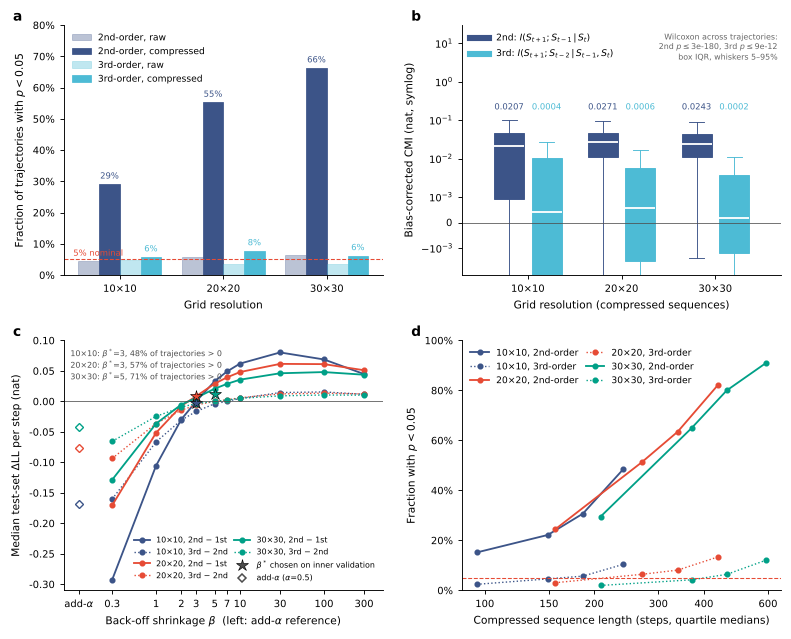

In [7]:
NPG = ['#E64B35', '#4DBBD5', '#00A087', '#3C5488', '#F39B7F', '#8491B4', '#91D1C2', '#DC0000', '#7E6148', '#B09C85']
C2, C3 = NPG[3], NPG[1]                      # 二阶 / 三阶
CG = {10: NPG[3], 20: NPG[0], 30: NPG[2]}    # 网格

def nature_style():
    plt.rcParams.update({
        'font.family': 'sans-serif', 'font.sans-serif': ['Arial', 'Helvetica', 'DejaVu Sans'],
        'font.size': 7, 'axes.labelsize': 7, 'axes.titlesize': 7.5, 'xtick.labelsize': 6.5, 'ytick.labelsize': 6.5,
        'legend.fontsize': 6, 'axes.linewidth': 0.6, 'xtick.major.width': 0.6, 'ytick.major.width': 0.6,
        'xtick.major.size': 2.5, 'ytick.major.size': 2.5, 'axes.spines.top': False, 'axes.spines.right': False,
        'legend.frameon': False, 'figure.dpi': 130, 'savefig.dpi': 600, 'savefig.bbox': 'tight',
        'pdf.fonttype': 42, 'ps.fonttype': 42, 'axes.unicode_minus': False, 'lines.linewidth': 1.2})

def panel_label(ax, s, x=-0.16, y=1.06):
    ax.text(x, y, s, transform=ax.transAxes, fontsize=9, fontweight='bold', va='top', ha='left')

def box(ax, data, pos, color, width=0.32, alpha=1.0):
    bp = ax.boxplot(data, positions=pos, widths=width, showfliers=False, patch_artist=True, whis=(5, 95),
                    medianprops=dict(color='white', lw=1.2), boxprops=dict(facecolor=color, edgecolor=color, lw=0.6, alpha=alpha),
                    whiskerprops=dict(color=color, lw=0.6, alpha=alpha), capprops=dict(color=color, lw=0.6, alpha=alpha))
    return bp

nature_style()
grids = sorted(df.grid.unique())
S = summary.set_index(['grid', 'compressed'])
fig, axs = plt.subplots(2, 2, figsize=(7.2, 5.8))
(a, b), (c, d) = axs
x = np.arange(len(grids)); w = 0.2

# --- a: 显著比例 ---
for i, (order, col) in enumerate([(2, C2), (3, C3)]):
    for j, comp in enumerate([False, True]):
        vals = [S.loc[(g, comp), f'cmi{order}_sig05'] for g in grids]
        off = (i * 2 + j - 1.5) * w
        a.bar(x + off, vals, w, color=col, alpha=1 if comp else 0.35, edgecolor=col, lw=0.5,
              label=f'{order}{"nd" if order == 2 else "rd"}-order, {"compressed" if comp else "raw"}')
        if comp:
            for xi, v in zip(x + off, vals):
                a.text(xi, v + 0.012, f'{v*100:.0f}%', ha='center', va='bottom', fontsize=5.5, color=col)
a.axhline(0.05, color=NPG[0], ls='--', lw=0.7); a.text(-0.45, 0.062, '5% nominal', fontsize=5.5, color=NPG[0], ha='left')
a.set_xticks(x); a.set_xticklabels([f'{g}×{g}' for g in grids]); a.set_xlabel('Grid resolution')
a.set_ylabel('Fraction of trajectories with $p<0.05$'); a.set_ylim(0, 0.8)
a.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v*100:.0f}%'))
a.legend(loc='upper left', ncol=1); panel_label(a, 'a')

# --- b: CMI 分布 (压缩) ---
for i, g in enumerate(grids):
    s = df[(df.grid == g) & df.compressed]
    box(b, [s.cmi2_excess.dropna()], [i - 0.2], C2); box(b, [s.cmi3_excess.dropna()], [i + 0.2], C3)
    for k, (col, name) in enumerate([(C2, 'cmi2'), (C3, 'cmi3')]):
        b.text(i - 0.2 + 0.4 * k, 0.17, f'{S.loc[(g, True), f"{name}_median"]:.4f}', ha='center', va='bottom', fontsize=5.5, color=col)
p2 = max(S.loc[(g, True), 'cmi2_wilcoxon_p'] for g in grids); p3 = max(S.loc[(g, True), 'cmi3_wilcoxon_p'] for g in grids)
b.text(0.99, 0.97, f'Wilcoxon across trajectories:\n2nd $p\\leq${p2:.0e}, 3rd $p\\leq${p3:.0e}\nbox IQR, whiskers 5–95%', transform=b.transAxes, ha='right', va='top', fontsize=5.2, color='0.4')
b.set_yscale('symlog', linthresh=1e-3, linscale=0.6); b.set_ylim(-5e-3, 30)
b.axhline(0, color='0.3', lw=0.5)
b.set_xticks(x); b.set_xticklabels([f'{g}×{g}' for g in grids]); b.set_xlabel('Grid resolution (compressed sequences)')
b.set_ylabel('Bias-corrected CMI (nat, symlog)')
b.plot([], [], color=C2, lw=4, label=r'2nd: $I(S_{t+1};S_{t-1}\,|\,S_t)$'); b.plot([], [], color=C3, lw=4, label=r'3rd: $I(S_{t+1};S_{t-2}\,|\,S_{t-1},S_t)$')
b.legend(loc='upper left')
panel_label(b, 'b')

# --- c: 测试段 ΔLL 随 back-off 强度 β 的变化 (压缩) ---
cc = curve[curve.compressed]; tt = tuned[tuned.compressed].set_index('grid')
for g in grids:
    p = cc[cc.grid == g]
    c.plot(p.beta, p.dll_2v1_median, marker='o', ms=3, color=CG[g], label=f'{g}×{g}, 2nd − 1st')
    c.plot(p.beta, p.dll_3v2_median, marker='o', ms=3, color=CG[g], ls=':', lw=0.9, label=f'{g}×{g}, 3rd − 2nd')
    # add-α 参考值放在最左侧，全局调参 β* 的测试段 ΔLL 用星号
    c.plot([0.12], [S.loc[(g, True), 'dll_2v1_median']], marker='D', ms=3.5, color=CG[g], ls='none', mfc='white', mew=0.9)
    c.plot([tt.loc[g, 'beta2_star']], [tt.loc[g, 'dll_2v1_global']], marker='*', ms=8, color=CG[g], ls='none', mec='k', mew=0.4, zorder=5)
c.axhline(0, color='0.3', lw=0.5)
c.set_xscale('log'); c.set_xlim(0.08, 500); c.set_xticks([0.12] + BETAS); c.set_xticklabels([r'add-$\alpha$'] + [f'{b:g}' for b in BETAS]); c.minorticks_off()
c.set_xlabel(r'Back-off shrinkage $\beta$  (left: add-$\alpha$ reference)')
c.set_ylabel(r'Median test-set $\Delta$LL per step (nat)'); c.set_ylim(-0.31, 0.1)
h_, l_ = c.get_legend_handles_labels()
h_ += [plt.Line2D([], [], marker='*', ms=8, color='0.3', mec='k', mew=0.4, ls='none'), plt.Line2D([], [], marker='D', ms=3.5, color='0.3', mfc='white', ls='none')]
l_ += [r'$\beta^*$ chosen on inner validation', r'add-$\alpha$ ($\alpha$=0.5)']
c.legend(h_, l_, loc='lower right', ncol=2, columnspacing=0.8, fontsize=5.2)
txt = '\n'.join(f"{g}×{g}: $\\beta^*$={tt.loc[g, 'beta2_star']:g}, {tt.loc[g, 'dll_2v1_global_pos']*100:.0f}% of trajectories > 0" for g in grids)
c.text(0.02, 0.97, txt, transform=c.transAxes, va='top', fontsize=5.2, color='0.3')
panel_label(c, 'c')

# --- d: 功效 vs 长度 ---
for g in grids:
    p = power[power.grid == g]
    d.plot(p.len_median, p.cmi2_sig05, marker='o', ms=3, color=CG[g], label=f'{g}×{g}, 2nd-order')
    d.plot(p.len_median, p.cmi3_sig05, marker='o', ms=3, color=CG[g], ls=':', lw=0.9, label=f'{g}×{g}, 3rd-order')
d.axhline(0.05, color=NPG[0], ls='--', lw=0.7)
d.set_xscale('log'); d.set_xticks([100, 150, 200, 300, 400, 600]); d.set_xticklabels(['100', '150', '200', '300', '400', '600']); d.minorticks_off()
d.set_xlabel('Compressed sequence length (steps, quartile medians)')
d.set_ylabel('Fraction with $p<0.05$'); d.set_ylim(0, 1.0)
d.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v*100:.0f}%'))
d.legend(loc='upper left', ncol=2, columnspacing=0.8); panel_label(d, 'd')

fig.tight_layout(w_pad=2.0, h_pad=1.5)
for ext in ('png', 'pdf'):
    fig.savefig(os.path.join(FIG_DIR, f'fig_taxi_memory.{ext}'))
print('已保存:', os.path.join(FIG_DIR, 'fig_taxi_memory.png / .pdf'))

## 8. 稳健性：全局固定网格

主结果把每条轨迹按自身包围盒归一化，网格编号只在轨迹内部有意义。这有两个后果：(i) 不能做跨轨迹的地理解释；(ii) 活动范围小的车辆被"放大"到整张网格上，
停留比例和状态数都和全局网格不同。为检验结论是否依赖这一选择，用全体数据经纬度的 0.5–99.5% 分位数作为固定边界（上海市区约 56 km × 66 km，30×30 时每格约 2 km）重跑全部分析。

**期望**：全局网格下每格更大，更多的 GPS 点落在同一格里，压缩后序列更短、停留比例更高 → 二阶 CMI 的个体显著比例应**下降**（功效降低），但中位数仍应显著为正；
back-off 下的 ΔLL 符号应保持。如果二阶记忆只是逐轨迹归一化的产物，全局网格下它应当消失。

In [8]:
GLOBAL_CSV = PER_FILE_CSV['global']
if os.path.exists(GLOBAL_CSV):
    df_g = load_results(GLOBAL_CSV)
    summary_g = summarize(df_g); summary_g.insert(0, 'grid_mode', 'global')
    both = pd.concat([summary, summary_g]).set_index(['grid_mode', 'grid', 'compressed']).sort_index(level=[1, 2])
    cols = ['n_files', 'stay_frac_median', 'len_median', 'cmi2_median', 'cmi2_sig05', 'cmi2_wilcoxon_p', 'cmi3_median', 'cmi3_sig05',
            'dll_2v1_median', 'dll_2v1_pos', 'dll_2v1_bo_median', 'dll_2v1_bo_pos', 'dll_3v2_bo_median', 'dll_3v2_bo_pos']
    display(both.loc[(slice(None), slice(None), True), cols].round(4))        # 只看压缩序列
    pd.concat([summary, summary_g]).to_csv(SUMMARY_CSV, index=False)
    print('两种网格的汇总已写入', SUMMARY_CSV)
    if os.path.exists(SWEEP_CSV['global']):
        curve_g, tuned_g = analyze_sweep(pd.read_csv(SWEEP_CSV['global']))
        tb = pd.concat([tuned.assign(grid_mode='per_traj'), tuned_g.assign(grid_mode='global')])
        tb = tb[tb.compressed].set_index(['grid', 'grid_mode']).sort_index()
        print('调参后的 back-off ΔLL（压缩序列）: 逐轨迹网格 vs 全局网格')
        display(tb[['n', 'beta1_star', 'beta2_star', 'beta3_star', 'dll_2v1_global', 'dll_2v1_global_pos', 'dll_2v1_global_wilcoxon_p', 'dll_3v2_global', 'dll_3v2_global_pos']].round(4))
        tb.reset_index().to_csv('memory_backoff_tuned_summary.csv', index=False)
    else:
        curve_g = tuned_g = None
else:
    df_g = None
    summary.to_csv(SUMMARY_CSV, index=False)
    print(f'未找到 {GLOBAL_CSV}；把 CFG["grid_mode"] 改为 "global" 并 RUN_COMPUTE=True 可生成。')

两种网格的汇总已写入 memory_full_summary.csv
调参后的 back-off ΔLL（压缩序列）: 逐轨迹网格 vs 全局网格


,,,n_files,stay_frac_median,len_median,cmi2_median,cmi2_sig05,cmi2_wilcoxon_p,cmi3_median,cmi3_sig05,dll_2v1_median,dll_2v1_pos,dll_2v1_bo_median,dll_2v1_bo_pos,dll_3v2_bo_median,dll_3v2_bo_pos
grid_mode,grid,compressed,,,,,,,,,,,,,,
global,10,True,1789,0.9546,79.0,0.0142,0.1593,0.0,0.0000,0.0565,-0.3477,0.0587,-0.1339,0.2029,-0.1207,0.0660
per_traj,10,True,2154,0.9006,167.0,0.0207,0.2906,0.0,0.0004,0.0576,-0.1691,0.0840,-0.1054,0.1481,-0.0664,0.0525
global,20,True,2053,0.9159,145.0,0.0156,0.2343,0.0,0.0003,0.0619,-0.2464,0.0580,-0.1142,0.1578,-0.0777,0.0482
per_traj,20,True,2230,0.8185,306.0,0.0271,0.5525,0.0,0.0006,0.0771,-0.0764,0.0973,-0.0515,0.1762,-0.0363,0.0372
global,30,True,2126,0.8821,203.0,0.0234,0.3655,0.0,0.0002,0.0597,-0.1618,0.0668,-0.0843,0.1439,-0.0558,0.0423
per_traj,30,True,2243,0.7535,416.0,0.0243,0.6625,0.0,0.0002,0.0615,-0.0416,0.1168,-0.0365,0.1672,-0.0246,0.0370


n  beta1_star  beta2_star  beta3_star  dll_2v1_global  dll_2v1_global_pos  dll_2v1_global_wilcoxon_p  dll_3v2_global  dll_3v2_global_pos
grid grid_mode                                                                                                                                             
10   global     1789           2           3           3         -0.0149              0.4360                     1.0000         -0.0357              0.2091
     per_traj   2154           2           3           5         -0.0029              0.4810                     0.8709         -0.0142              0.3561
20   global     2053           2           3           5         -0.0101              0.4384                     1.0000         -0.0229              0.3093
     per_traj   2230           3           3           5          0.0084              0.5726                     0.0000         -0.0032              0.4336
30   global     2126           2           3           5          0.0027              0.5212                     0.0005         -0.0139              0.3401
     per_traj   2243           3           5           5          0.0123              0.7066                     0.0000          0.0000              0.4686

已保存: figs/fig_taxi_gridmode.png / .pdf


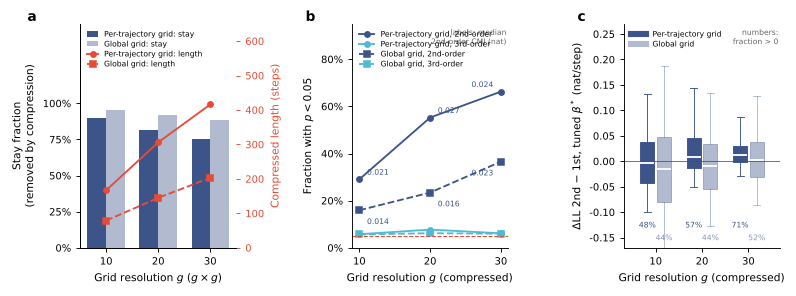

In [9]:
if df_g is not None and tuned_g is not None:
    nature_style()
    fig2, axs2 = plt.subplots(1, 3, figsize=(7.2, 2.7))
    e, f, h = axs2
    MODES = [('per_traj', 'Per-trajectory grid', 'o', '-'), ('global', 'Global grid', 's', '--')]
    xs = np.arange(len(grids)); w = 0.36
    # --- e: 停留比例 & 压缩后长度 ---
    for k, (mode, lab, mk, ls) in enumerate(MODES):
        Sm = both.loc[mode]
        e.bar(xs + (k - 0.5) * w, [Sm.loc[(g, True), 'stay_frac_median'] for g in grids], w, color=NPG[3], alpha=1 if mode == 'per_traj' else 0.4, label=f'{lab}: stay')
    e2 = e.twinx(); e2.spines['top'].set_visible(False)
    for k, (mode, lab, mk, ls) in enumerate(MODES):
        Sm = both.loc[mode]
        e2.plot(xs, [Sm.loc[(g, True), 'len_median'] for g in grids], marker=mk, ls=ls, ms=3.5, color=NPG[0], label=f'{lab}: length')
    e.set_ylim(0, 1.55); e.set_yticks([0, .25, .5, .75, 1]); e.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v*100:.0f}%'))
    e2.set_ylim(0, 650)
    e.set_ylabel('Stay fraction\n(removed by compression)'); e2.set_ylabel('Compressed length (steps)', color=NPG[0]); e2.tick_params(axis='y', colors=NPG[0])
    e.set_xticks(xs); e.set_xticklabels([f'{g}' for g in grids]); e.set_xlabel('Grid resolution $g$ ($g\\times g$)')
    hdl = e.get_legend_handles_labels(); hdl2 = e2.get_legend_handles_labels()
    e.legend(hdl[0] + hdl2[0], hdl[1] + hdl2[1], loc='upper left', ncol=1, fontsize=5, handlelength=1.4, labelspacing=0.3); panel_label(e, 'a', x=-0.34)
    # --- f: 二阶/三阶显著比例 ---
    for k, (mode, lab, mk, ls) in enumerate(MODES):
        Sm = both.loc[mode]
        f.plot(xs, [Sm.loc[(g, True), 'cmi2_sig05'] for g in grids], marker=mk, ls=ls, ms=3.5, color=C2, label=f'{lab}, 2nd-order')
        f.plot(xs, [Sm.loc[(g, True), 'cmi3_sig05'] for g in grids], marker=mk, ls=ls, ms=3.5, color=C3, label=f'{lab}, 3rd-order')
        for xi, g in zip(xs, grids):
            f.annotate(f"{Sm.loc[(g, True), 'cmi2_median']:.3f}", (xi, Sm.loc[(g, True), 'cmi2_sig05']), textcoords='offset points',
                       xytext=((5, 3) if mode == 'per_traj' else (5, -9)) if g < 30 else ((-5, 3) if mode == 'per_traj' else (-5, -9)), ha='left' if g < 30 else 'right', fontsize=5, color=C2)
    f.axhline(0.05, color=NPG[0], ls='--', lw=0.7)
    f.set_ylim(0, 0.95); f.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v*100:.0f}%'))
    f.set_xticks(xs); f.set_xticklabels([f'{g}' for g in grids]); f.set_xlabel('Grid resolution $g$ (compressed)')
    f.set_ylabel('Fraction with $p<0.05$'); f.text(0.99, 0.98, 'labels: median\n2nd-order CMI (nat)', transform=f.transAxes, ha='right', va='top', fontsize=5, color='0.4')
    f.legend(loc='upper left', fontsize=5, labelspacing=0.3); panel_label(f, 'b', x=-0.3)
    # --- h: 调参后 back-off 的 ΔLL 2v1 分布 ---
    for k, (mode, lab, mk, ls) in enumerate(MODES):
        sw_ = sweep if mode == 'per_traj' else pd.read_csv(SWEEP_CSV['global'])
        tu_ = (tuned if mode == 'per_traj' else tuned_g); tu_ = tu_[tu_.compressed].set_index('grid')
        for i, g in enumerate(grids):
            s = sw_[(sw_.grid == g) & sw_.compressed]
            b1, b2 = tu_.loc[g, 'beta1_star'], tu_.loc[g, 'beta2_star']
            d21 = s[f'll2_b{b2:g}'] - s[f'll1_b{b1:g}']
            box(h, [d21], [i + (k - 0.5) * 0.36], C2, width=0.3, alpha=1 if mode == 'per_traj' else 0.4)
            h.text(i + (k - 0.5) * 0.36, -0.13 - 0.025 * k, f"{(d21 > 0).mean()*100:.0f}%", ha='center', fontsize=5, color=C2, alpha=1 if mode == 'per_traj' else 0.6)
    h.axhline(0, color='0.3', lw=0.5); h.set_ylim(-0.17, 0.27)
    h.set_xticks(xs); h.set_xticklabels([f'{g}' for g in grids]); h.set_xlabel('Grid resolution $g$ (compressed)')
    h.set_ylabel(r'$\Delta$LL 2nd − 1st, tuned $\beta^*$ (nat/step)')
    h.plot([], [], color=C2, lw=4, label='Per-trajectory grid'); h.plot([], [], color=C2, lw=4, alpha=0.4, label='Global grid')
    h.legend(loc='upper left', fontsize=5, labelspacing=0.3); h.text(0.99, 0.98, 'numbers:\nfraction > 0', transform=h.transAxes, ha='right', va='top', fontsize=5, color='0.4')
    panel_label(h, 'c', x=-0.3)
    fig2.tight_layout(w_pad=1.6)
    for ext in ('png', 'pdf'):
        fig2.savefig(os.path.join(FIG_DIR, f'fig_taxi_gridmode.{ext}'))
    print('已保存:', os.path.join(FIG_DIR, 'fig_taxi_gridmode.png / .pdf'))

### 结果解读

- 全局网格下每格更大（30×30 约 2 km），停留比例从 75–90% 升到 88–95%，压缩后长度中位数从 167 / 306 / 416 降到 79 / 145 / 203，满足长度要求的轨迹数也略减。
- 在这种功效更低的设置下，二阶 CMI 中位数仍为 0.014 / 0.016 / 0.023 nat、跨轨迹 $p$ 数值下溢；个体显著比例降为 16% / 23% / 37%——下降幅度与序列变短一致（对照第 5 节的功效曲线：长度 80–200 步时逐轨迹网格的显著比例也只有 15–30%）。三阶显著比例 6% 左右，与逐轨迹网格相同。
- 调参后的 back-off ΔLL(2 vs 1)：全局网格下中位数 −0.015 / −0.010 / +0.003，二阶更优比例 44% / 44% / 52%，只有 30×30 显著（$p=5\times10^{-4}$）。序列更短、每格更粗，二阶模型可兑现的收益进一步缩小，但方向没有反转。
- 因此二阶来路记忆不是逐轨迹归一化造成的人工结构，而是城市路网几何约束下真实的路径依赖；逐轨迹网格的数值更高是因为它给了每条轨迹更细的分辨率和更长的转移序列。

## 9. 结论与局限

**结论**

1. 出租车轨迹在剥离停留后存在稳定的**二阶来路记忆**：$I(S_{t+1};S_{t-1}\mid S_t)$ 中位数 0.02–0.03 nat，个体显著比例 29–66%，且随序列长度上升到 91%；换成全局固定网格后结论不变。
2. **主导记忆深度为二阶**：三阶 CMI 仅为二阶的 1–2%，显著比例仅在最长轨迹上明显高于名义水平——三阶残余真实但微弱，且在任何平滑下都没有预测收益。
3. "信息存在"≠"预测收益"，而且后者的符号由估计量决定：add-α 与弱 back-off（β≤2）下二阶模型"输给"一阶，是先验过于分散的结果；每个阶各自调好 β 后，二阶模型有微弱但显著的样本外收益（+0.01–0.03 nat/step，约为 CMI 上限的 30–60%）。
   要把来路记忆工程化，需要样本效率更高的模型族（Kneser–Ney 类折扣、可变阶马尔科夫链、层次共享参数或轨迹聚类后的群体级二阶模型）。

**局限 / 复现要点**

- 主结果用的是按轨迹包围盒归一化的网格，网格编号没有跨轨迹的地理含义；全局网格（第 8 节）每格约 2 km，分辨率较粗，若要做地理解释需要更细的全局网格或路网匹配。
- back-off 的 β 只在 10 个离散值上搜索，且只用了最简单的"向低阶线性插值"形式；报告的 ΔLL 是"调好先验的朴素模型"的收益，不是二阶模型的最佳可能收益。
- 随机种子由文件名决定；本次重跑与旧版缓存相比，add-α 的逐轨迹 LL 完全相同（最大差 0），CMI 因种子不同有微小差异（相关系数 0.9999），聚合结论不变。
- 单文件置换次数为 100，$p$ 值分辨率为 1/101；跨轨迹 Wilcoxon 检验不受此限制。